# W11B A · 소리가 문자와 오류율이 되는 과정
    2026-11-11 · 주교재9장 전체 중9.1·9.2·9.4·장말 문제.
    새 Colab 사본에서 첫 셀부터 독립 실행합니다. CPU 실제 Wav2Vec2·Whisper 추론이며 키·유료 GPU·개인 음성·이전 파일이 필요 없습니다. 첫 실행은 모델 다운로드가 필요합니다.
    **예측 → 본문 계산 → 중간 배열 → 한 조건 변경 → 새 사례 설명**을 기록하세요. 펼쳐진 함수가 실제 모델·평가에 전달됩니다. 함수의 import만 읽는 실습이 아닙니다. 설치만 접을 수 있습니다.
    [강의노트](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11b/course/notion/w11b/w11b-lesson.md) · [계산 기록지](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11b/course/notion/w11b/w11b-workbook.md)


In [ ]:
#@title 설치와 공개 샘플 준비 { display-mode: "form" }
import sys, subprocess, os, json, math, re, unicodedata, uuid
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
PUBLIC_REF='2026-fall-w11b'
local=Path('src/pyproject.toml').is_file()
needed={'luna-genai':'0.1.19','scipy':'1.18.1','librosa':'1.0.0','soundfile':'0.14.0','sentencepiece':'0.2.3'}
try: ready=all(version(name)==expected for name,expected in needed.items())
except PackageNotFoundError: ready=False
if not ready:
    if 'luna_genai' in sys.modules: raise RuntimeError('런타임을 재시작한 뒤 첫 셀부터 실행하세요.')
    package=str(Path('src').resolve())+'[audio]' if local else 'luna-genai[audio] @ '+'git+https://github.com/lunalab-ai/genAI.git@'+PUBLIC_REF+'#subdirectory=src'
    subprocess.run([sys.executable,'-m','pip','install','-q']+(['-e'] if local else [])+[package],check=True)
if local: sys.path.insert(0,str(Path('src').resolve()))  # editable .pth is normally read at kernel startup
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, soundfile as sf
from IPython.display import display, Audio
from luna_genai.audio_core import load_audio_sample,asset_directory
from luna_genai.audio_models import recognize,synthesize,load_asr,load_tts
torch.set_num_threads(4)
sample=load_audio_sample(); wave=sample['waveform']; fs=sample['sampling_rate']
RUN_ID=uuid.uuid4().hex; IN_COLAB='COLAB_RELEASE_TAG' in os.environ
print('Python',sys.version.split()[0],'luna-genai',version('luna-genai'),'CPU',not torch.cuda.is_available(),'run',RUN_ID)
print('공개 샘플',len(wave),fs,len(wave)/fs,sample['reference'])
display(Audio(wave,rate=fs))


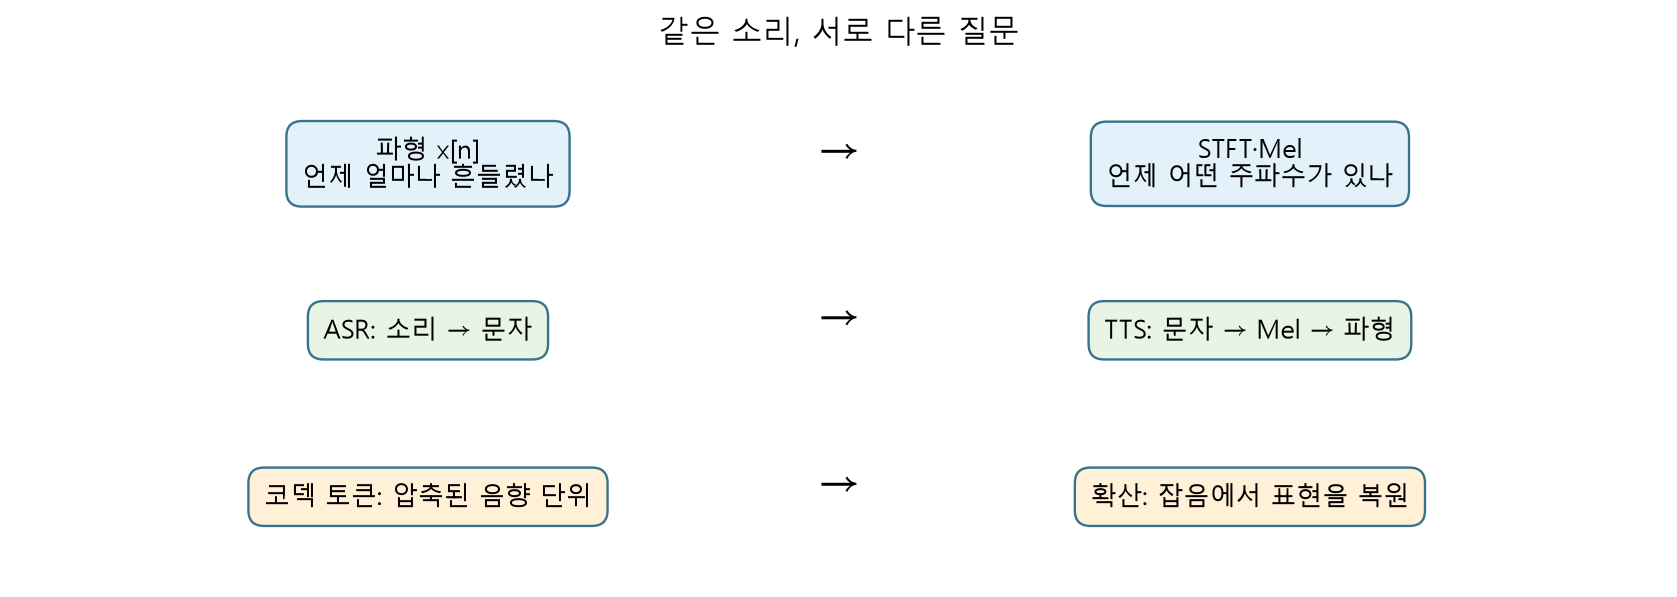

    $$T=\frac{N}{f_s}$$

    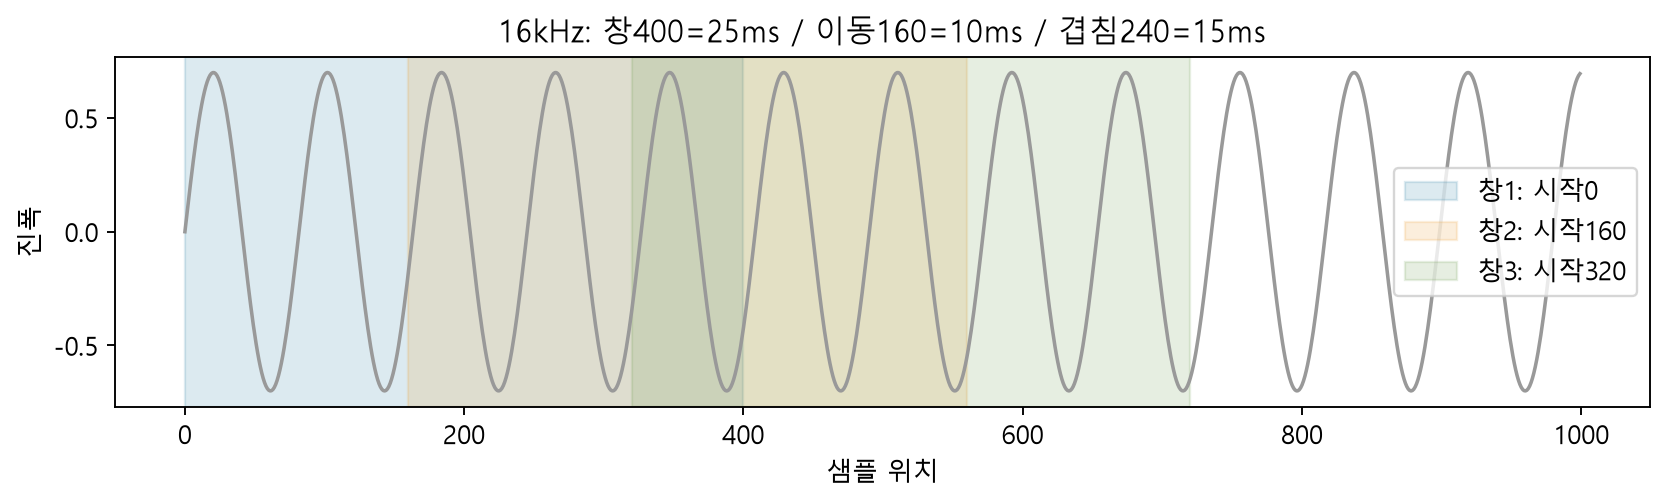


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w11b/course/notion/w11b/assets/01-map.png) · [Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w11b/course/notion/w11b/assets/04-window.png)


## 1. 샘플 수·시간·창의 이동
    소리는 시간에 따른 진폭입니다. 16kHz는 1초에16000개를 기록했다는 뜻입니다. `resample_audio`는 새 시간축에 맞게 값을 다시 계산합니다. rate 숫자만 바꾸면 속도와 음높이가 함께 바뀝니다.
    아래 함수는 패키지 소스와 같은 본문을 제작 시 대조합니다. **여기서 수정한 함수**를 이어지는 셀에서 호출합니다.


In [ ]:
def mono_float(signal):
    """PCM/float (N,) 또는 (N,C)를 유한 float32 mono (N,)로 변환한다.

    soundfile/Gradio의 마지막 축이 채널이다. 정수 PCM만 dtype 범위로 나누며
    float의 음량을 매번 최대값으로 정규화하지 않는다. 빈 배열/NaN은 ValueError.
    디스크·네트워크 부작용 없음. 예: int16 [0,16384] -> [0,.5].
    """
    x = np.asarray(signal)
    if x.ndim not in (1, 2) or not x.size or x.dtype.kind not in 'fiu':
        raise ValueError('Audio must be a nonempty (samples,) or (samples,channels) array')
    if x.dtype.kind in 'iu':
        bits = np.iinfo(x.dtype).bits
        midpoint = 2 ** (bits - 1)
        x = (x.astype(np.float32) - (midpoint if x.dtype.kind == 'u' else 0)) / midpoint
    else:
        x = x.astype(np.float32)
    if x.ndim == 2:
        if not 1 <= x.shape[1] <= 8:
            raise ValueError('Last axis must be channels, not time')
        x = x.mean(axis=1)
    if not np.isfinite(x).all():
        raise ValueError('Audio contains NaN or infinity')
    return x

def resample_audio(signal, source_rate, target_rate=16000):
    """실제 polyphase resampling. rate 라벨만 바꾸지 않는다.

    rate: 양의 정수 Hz, target 기본16000. 반환 float32 (N_new,),
    N_new=ceil(N*target/source). 저역통과 처리는 scipy.signal.resample_poly.
    업샘플링은 원본에 없던 고주파 정보를 복구하지 않는다. 외부 I/O 없음.
    """
    from scipy.signal import resample_poly
    if any(isinstance(r, (bool, np.bool_)) or int(r) != r or r <= 0 for r in (source_rate, target_rate)):
        raise ValueError('Rates must be positive integer Hz')
    x = mono_float(signal)
    divisor = math.gcd(int(source_rate), int(target_rate))
    return resample_poly(x, int(target_rate)//divisor, int(source_rate)//divisor).astype(np.float32)

def frame_signal(signal, frame_length=400, hop_length=160, center=False):
    """파형을 (frames, frame_length)로 복사한다. hop은 창의 이동 간격이다.

    center=False: 완전한 창만 사용, frames=1+(N-frame_length)//hop.
    True: 양끝 frame_length//2 reflect padding(너무 짧으면 constant).
    frame_length와 hop은 양의 정수. N이 창보다 짧으면 ValueError.
    """
    x = mono_float(signal)
    if any(isinstance(v, bool) or int(v) != v or v <= 0 for v in (frame_length, hop_length)):
        raise ValueError('Frame and hop lengths must be positive integers')
    frame_length, hop_length = int(frame_length), int(hop_length)
    if center:
        pad = frame_length // 2
        x = np.pad(x, (pad, pad), mode='reflect' if len(x) > pad else 'constant')
    if len(x) < frame_length:
        raise ValueError('Signal is shorter than one complete frame')
    starts = range(0, len(x)-frame_length+1, hop_length)
    return np.stack([x[start:start+frame_length] for start in starts])

def stft_power(signal, n_fft=400, hop_length=160, center=False):
    """Hann 창→rFFT→|X|². 반환 power (1+n_fft//2, frames).

    FFT는 numpy, 창·프레임·축 전환·power는 이 함수 본문에서 계산한다.
    FFT 정규화 없는 power이며 physical SPL/dBFS가 아니다. 외부 I/O 없음.
    """
    frames = frame_signal(signal, n_fft, hop_length, center)
    window = np.hanning(n_fft + 1)[:-1]  # periodic Hann, 같은 n_fft를 사용
    complex_frames = np.fft.rfft(frames * window, axis=1)
    return (np.abs(complex_frames) ** 2).T


In [ ]:
print('actual seconds',len(wave)/fs)
frames=frame_signal(wave); power=stft_power(wave)
print('frames',frames.shape,'power',power.shape)
low=resample_audio(wave,fs,8000); restored=resample_audio(low,8000,16000)
display(Audio(low,rate=8000));display(Audio(low,rate=16000))
print('정상 길이',len(low)/8000,'잘못 붙인 라벨',len(low)/16000)
plt.figure(figsize=(9,2));plt.plot(wave[:1200]);plt.axvspan(0,400,alpha=.2);plt.axvspan(160,560,alpha=.2);plt.show()
my_duration=None;my_frames=None


### 9A1 · 새 샘플 수를 설명하세요
    8kHz 음성24000개는 몇 초인가요? 16kHz라고 라벨만 바꿨을 때와 실제16kHz로 resample했을 때의 길이·샘플 수를 구별하세요. `frame_signal(np.zeros(1600),400,160)`의 프레임 수도 먼저 계산하세요.
    힌트: 시간=개수/rate, 완전한 창만 세며 첫 창을 포함합니다. 결과만 적지 말고 청취 변화의 이유를 쓰세요.


## 2. 파형에서 Whisper 입력까지 직접 계산
    창400 → rFFT201bins → Mel 필터80개 → log10·clipping·scaling. Whisper-tiny의 입력 계약은 (batch1,Mel80,time3000)입니다. 3000은 30초로 padding한 결과이며 실제 발화시간이 아닙니다.
    FFT 자체는 NumPy, Mel 필터 구성만 공식 helper를 사용합니다. 나머지 프레임·행렬곱·축·로그 계산은 아래에서 수정합니다.


In [ ]:
def whisper_logmel(signal, sampling_rate=16000, n_mels=80, hop_length=160, chunk_seconds=30):
    """Whisper용 단일 입력을 설명 가능한 계산으로 만든다: (1,Mel,time).

    16kHz mono만 받는다. truncate/right-pad→Hann STFT→Mel 행렬곱→
    log10→dynamic-range clipping→Whisper scaling. 기본은 (1,80,3000).
    Mel 필터 구성만 Transformers 공식 helper를 사용한다. 임의 n_mels/hop
    탐구 결과가 사전학습 모델의 입력 계약과 맞는지는 별도 확인해야 한다.
    """
    from transformers.audio_utils import mel_filter_bank
    if sampling_rate != 16000 or not 1 <= n_mels <= 200 or hop_length < 1 or chunk_seconds < 1:
        raise ValueError('Use 16kHz audio and positive feature settings')
    length = int(sampling_rate * chunk_seconds)
    x = mono_float(signal)[:length]
    x = np.pad(x, (0, length-len(x)))
    power = stft_power(x, n_fft=400, hop_length=hop_length, center=True)[:, :-1]
    filters = mel_filter_bank(201, int(n_mels), 0., 8000., 16000, norm='slaney', mel_scale='slaney')
    mel = filters.T @ power
    logmel = np.log10(np.maximum(mel, 1e-10))
    logmel = np.maximum(logmel, logmel.max()-8.)
    return ((logmel+4.)/4.).astype(np.float32)[None, :, :]


In [ ]:
features=whisper_logmel(wave)
processor,_=load_asr('whisper')
official=processor(wave,sampling_rate=fs,return_tensors='np').input_features
max_difference=float(np.max(np.abs(features-official)))
print('shape',features.shape,'official max error',max_difference)
assert features.shape==(1,80,3000) and max_difference<1e-4
experiments=[]
for mel_count,hop,seconds in [(80,160,30),(40,160,30),(80,320,30),(80,160,15)]:
    shape=whisper_logmel(wave,n_mels=mel_count,hop_length=hop,chunk_seconds=seconds).shape
    experiments.append(dict(mels=mel_count,hop=hop,seconds=seconds,shape=shape))
display(pd.DataFrame(experiments))
plt.figure(figsize=(9,3));plt.imshow(features[0,:,:600],origin='lower',aspect='auto');plt.xlabel('time frame');plt.ylabel('Mel bin');plt.show()


### 9A2 · 모양을 먼저 예상하세요
40Mel·hop320·30초일 때 shape를 적으세요. 그 배열을 그대로 Whisper-tiny에 넣어도 될까요? hop 변화는 주파수 해상도까지 바꾸나요?


In [ ]:
my_shape=None


## 3. CTC의 blank는 띄어쓰기가 아니다
    연속 ID 병합 → blank 제거 순서입니다. l,l,blank,l이면 ll입니다. 단어 구분자는 별도 토큰입니다. 아래 `ctc_decode`를 실제 Wav2Vec2 출력 ID에 전달합니다. 이것은 greedy 추론이며 CTC 학습의 경로 확률 합산과 구별합니다.


In [ ]:
def ctc_decode(token_ids, id_to_token, blank_id=0, word_delimiter='|'):
    """Greedy CTC 추론의 collapse: 연속 동일 ID 병합→blank 제거→단어 기호.

    token_ids: 1차원 정수 ID, id_to_token: dict[int,str]. 문자열 반환.
    blank_id 기본0은 모델의 실제 tokenizer.pad_token_id로 교체해야 한다.
    이것은 CTC 학습의 모든 정렬 경로 합산/beam search 구현이 아니다.
    예: IDs [1,1,0,1], {0:'_',1:'l'} -> 'll'.
    """
    output = []
    previous = None
    for raw in token_ids:
        token = int(raw)
        if token != previous and token != blank_id:
            piece = id_to_token[token]
            output.append(' ' if piece == word_delimiter else piece)
        previous = token  # blank도 이전 상태에 남겨야 반복 글자를 보존한다
    return ''.join(output).strip()


In [ ]:
print(ctc_decode([1,1,0,1],{0:'_',1:'l'}))
ctc=recognize(wave,fs,'ctc',decode_fn=ctc_decode)
whisper=recognize(wave,fs,'whisper',feature_fn=whisper_logmel)
official_ctc=load_asr('ctc')[0].batch_decode([ctc['token_ids']])[0]
assert ctc['text']==official_ctc
display(pd.DataFrame([ctc,whisper]).drop(columns='token_ids'))
# 실제 callback 연결 확인: 읽기용 코드가 아닌 실행 경로임을 검증합니다.
changed=recognize(wave,fs,'ctc',decode_fn=lambda *args:'CALLBACK_CHANGED')
assert changed['text']=='CALLBACK_CHANGED'
assert ctc_decode([1,1,0,1],{0:'_',1:'l'})=='ll'
my_ctc=None


### 9A3 · 경로를 손으로 접으세요
    blank=0, {0:"_",1:"A",2:"|",3:"B"}에서 [1,1,0,1,2,2,3]의 출력은? blank를 먼저 제거하면 어떤 정보가 사라지나요? 학습의 P(문장)는 가장 큰 프레임 경로 하나의 확률인가요?


## 4. 오류율도 직접 계산합니다
    기준 문장의 단어 수 N을 분모로 사용합니다. 대치 S·삭제 D·삽입 I의 최소 편집 비용을 계산합니다. `we can hear the model` → `we hear a model`은 D1+S1, WER2/5=.4입니다.
    같은 정규화를 양쪽에 적용하세요. 여기서는 약어 Mr.를 Mister로 확장하지 않습니다. CER은 정규화 후 공백을 제외한 문자 단위입니다.


In [ ]:
def normalize_text(text):
    """NFC+casefold, 구두점은 공백, 연속 공백은 하나로. 문자열 반환.

    같은 함수를 reference와 hypothesis 양쪽에 적용한다. 숫자/약어를
    의미적으로 확장하지 않는다. 한국어의 어절/문자 분절 기준도 별도 선택한다.
    """
    text = unicodedata.normalize('NFC', str(text)).casefold()
    text = ''.join(' ' if unicodedata.category(c).startswith('P') else c for c in text)
    return re.sub(r'\s+', ' ', text).strip()

def edit_alignment(reference, hypothesis):
    """두 토큰 list의 Levenshtein DP. 반환 distance, counts, alignment, table.

    insertion/deletion/substitution 비용1, match0. 동률은 대치→삭제→삽입
    순서로 결정하며 최적 정렬은 유일하지 않을 수 있다. table (N+1,M+1).
    counts 키 S,D,I,C; alignment는 (operation,reference,hypothesis) 목록.
    """
    a, b = list(reference), list(hypothesis)
    table = np.zeros((len(a)+1, len(b)+1), dtype=int)
    table[:, 0] = np.arange(len(a)+1)
    table[0, :] = np.arange(len(b)+1)
    for i, x in enumerate(a, 1):
        for j, y in enumerate(b, 1):
            table[i, j] = min(table[i-1,j]+1, table[i,j-1]+1, table[i-1,j-1]+(x != y))
    i, j = len(a), len(b)
    counts = dict(S=0, D=0, I=0, C=0)
    alignment = []
    while i or j:
        if i and j and table[i,j] == table[i-1,j-1]+(a[i-1] != b[j-1]):
            op = 'C' if a[i-1] == b[j-1] else 'S'
            alignment.append((op, a[i-1], b[j-1])); i -= 1; j -= 1
        elif i and table[i,j] == table[i-1,j]+1:
            op = 'D'; alignment.append((op, a[i-1], '')); i -= 1
        else:
            op = 'I'; alignment.append((op, '', b[j-1])); j -= 1
        counts[op] += 1
    return dict(distance=int(table[-1,-1]), counts=counts, alignment=alignment[::-1], table=table)

def text_error(reference, hypothesis, unit='word', normalizer=normalize_text):
    """WER/CER 상세. word=공백 단어/어절, char=정규화 후 공백 제외 문자.

    같은 normalizer를 양쪽에 적용한다. reference가 비면 분모가 없으므로
    ValueError. rate는 (S+D+I)/N이며 1을 넘을 수 있다. 퍼센트가 아닌 비율.
    반환 dict의 table은 numpy 배열, 나머지는 JSON으로 바꿀 수 있는 값이다.
    """
    ref, hyp = normalizer(reference), normalizer(hypothesis)
    if unit not in ('word', 'char'):
        raise ValueError('unit must be word or char')
    a, b = (ref.split(), hyp.split()) if unit == 'word' else (list(ref.replace(' ','')), list(hyp.replace(' ','')))
    if not a:
        raise ValueError('Empty reference: WER/CER denominator is undefined')
    result = edit_alignment(a, b)
    return dict(result, rate=result['distance']/len(a), denominator=len(a), reference=ref, hypothesis=hyp, unit=unit)


In [ ]:
rows=[]
for result in [ctc,whisper]:
    for unit in ['word','char']:
        score=text_error(sample['reference'],result['text'],unit=unit)
        rows.append(dict(model=result['kind'],unit=unit,error=score['rate'],N=score['denominator'],**score['counts']))
display(pd.DataFrame(rows))
example=text_error('we can hear the model','we hear a model')
display(pd.DataFrame(example['alignment'],columns=['op','reference','hypothesis']))
assert example['rate']==.4
my_error=None


### 9A4 · 새 오류를 직접 세세요
기준 `we hear music`, 인식 `we really hear loud music`의 S,D,I,N,WER을 계산하세요. 정규화 규칙을 바꾸면 같은 모델의 점수가 달라질 수 있나요?


## 선택 확장 · 한국어 ASR의 조건
    동의받은 한국어 mono 음성이 있다면 `recognize(korean_wave,korean_rate,'whisper',feature_fn=whisper_logmel,language='ko')`로 언어 조건을 명시할 수 있습니다. 한국어는 WER의 어절 분절과 CER의 공백·Unicode 정책을 먼저 정합니다. 영어 샘플을 한국어로 강제 전사한 결과를 한국어 성능 검증으로 사용하지 않습니다. 이 확장의 한국어 데이터 실행은 이번 기본 검증 범위에 포함되지 않습니다.

    [고정 버전의 전처리·CTC·평가 소스](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11b/src/luna_genai/audio_core.py) · [실제 모델 호출](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11b/src/luna_genai/audio_models.py)


## 5. 수정한 계산을 실제 앱에 전달
    `feature_fn`, `decode_fn`, `error_fn`은 위에서 실행한 함수를 그대로 전달합니다. 앱의 평가도 같은 함수를 호출합니다. 기본은 공개 샘플이며 개인 업로드는 선택입니다. 공유 앱에는 민감한 녹음을 넣지 마세요.


In [ ]:
from luna_genai.audio_app import build_audio_app
app=build_audio_app(feature_fn=whisper_logmel,decode_fn=ctc_decode,error_fn=text_error)
app_text,app_metric=app.w11b_callbacks['transcribe'](None,sample['reference'])
assert app_text==whisper['text'] and np.isfinite(app_metric['WER'])
if IN_COLAB: app.launch(share=True,inline=False,prevent_thread_lock=True)
print('앱의 인식·점수와 위 표가 같은지 확인하세요. 공유 주소는 런타임 동안 유지됩니다.')


In [ ]:
assert features.shape==(1,80,3000) and max_difference<1e-4
assert ctc['text'].strip() and whisper['text'].strip()
assert text_error('a','a a a')['rate']==2
print('W11B_A_RUNTIME_PASS',RUN_ID)
